# Generative Project — Milestone 3

This notebook compares fine-tuning strategies(full fine-tuning vs. LoRA vs. prefix tuning) for the CLIP-prefix captioning model from Milestone 2. All experiments use the same data, seed, and early-stopping rule. All five models are then evaluated on the test set (100 images) with BLEU, METEOR, ROUGE-L, CIDEr and CLIPScore, together with a comparison of decoding strategies and a sensitivity analysis of beam width and temperature.

- Prefix length(GPT-2 frozen) : 5, 10(Milestone2), 20
- Fine-tuning strategy(prefix 10) : mapping network only(Milestone 2), LoRA on GPT-2, full fine-tuning of GPT-2

In this project, 'prefix tuning' means training only the mapping network that produces the prefix while GPT-2 stays frozen(ClipCap-style). It is not the prefix-tuning method that adds trainable prefixes to every GPT-2 layer.

For the embedding injection method, **we did not implement cross-attention**, because it adds randomly initialized layers inside GPT-2 that need more data than our 4,000 training pairs. Instead, we analyze the sensitivity of prefix conditioning to the prefix length (5, 10, 20).


**Limitation**

Each setting was trained once with a single seed, so small differences (e.g., prefix 10 vs. 20) may not be significant. We also used one hyperparameter setting per strategy (LoRA rank 8; GPT-2 learning rate 2e-5 for full fine-tuning) without tuning, and GPT-2’s dropout was active only when GPT-2 was trained. The metrics are computed on 100 test images, so differences of a few points may also not be significant.


**Steps**

*Part A — Training*

0. Setup, Configuration and Mount Google Drive
1. Load the Milestone 1 outputs
2. Tokenize captions
3. Datasets and DataLoaders
4. Model
5. Build the model for each experiment
6. Training function
7. Run the experiments
8. Comparison table
9. Validation loss curves
10. Caption check

*Part B — Evaluation*

11. Evaluation setup
12. Generation and metric functions
13. Generate captions: 5 models × 3 decoding strategies
14. Main results: fine-tuning strategies and prefix lengths
15. Decoding strategies across models
16. Parameter sensitivity: beam width and temperature
17. Qualitative alignment between image and caption

**Outputs (Part A) :** `prefix5.pt`, `prefix20.pt`, `lora.pt`, `full_ft.pt`, `training_log_*.csv`, `summary_*.json`, `training_comparison.csv`, `loss_curves.png`, `caption_check.png`

**Outputs (Part B, `milestone3/eval/`) :** `generated_all.csv`, `metrics_all.csv`,
`metrics_main.csv`, `metrics_decoding.csv`, `metrics_by_decoding.png`,
`sensitivity_captions.csv`, `sensitivity.csv`, `sensitivity.png`, `qualitative_examples.png`

# Part A — Training

## 0. Setup, Configuration and Mount Google Drive

- Setup : Install *peft* for LoRA and remove the incompatible *torchao* package. Import libraries and fix the random seed(42).

- Configuration : Milestone 2 settings are mostly kept unchanged. Milestone 3 adds the experiment list, a smaller learning rate for GPT-2 in full fine-tuning, and the LoRA settings. Set *run = False* for finished experiments so they are not retrained.


In [2]:
!pip install -q peft
!pip uninstall -y -q torchao

> After running the install cell, restart the session (Runtime → Restart session) before running the other cells. Otherwise peft may still fail to import because of the old torchao.

In [3]:
import os, json, time, math, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)
if device == 'cuda':
    print(torch.cuda.get_device_name(0))

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device: cuda | torch 2.14.1+cu130
Tesla T4


In [4]:
# Configuration
DATA_SOURCE = 'drive'   # 'drive' (Milestone 1 output folder) or 'github' (data/ folder of the repo)

DRIVE_DIR = '/content/drive/MyDrive/IE7615_generative'           # Milestone 1 outputs
REPO_URL  = 'https://github.com/ljmljm7/ie7615-generative-project'

OUT_DIR   = f'{DRIVE_DIR}/milestone2'                             # Milestone 2 outputs
OUT_DIR_M3 = f'{DRIVE_DIR}/milestone3'                           # Milestone 3 outputs

CSV_NAME, EMB_NAME = 'coco_captions_clean.csv', 'clip_image_embs.pt'

# Model
GPT_NAME   = 'gpt2'
# PREFIX_LEN = 10        # Milestone2 setting; Milestone3 uses EXPERIMENTS(below) instead
CLIP_DIM   = 512
DROPOUT    = 0.1
# FREEZE_GPT = True      # Milestone2 setting; Milestone3 uses EXPERIMENTS(below) instead
NORMALIZE_EMB = True   # L2-normalize CLIP embeddings before the mapping network

# Data / training
MAX_LEN    = 30        # caption tokens incl. end-of-sequence (covers 99.9% of captions)
BATCH_SIZE = 32
EPOCHS     = 20
LR         = 2e-4
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 100
GRAD_CLIP  = 1.0
PATIENCE   = 3         # early stopping on validation loss

In [5]:
from google.colab import drive
drive.mount('/content/drive')

if DATA_SOURCE == 'github':
    if not os.path.exists('/content/repo'):
        !git clone -q {REPO_URL} /content/repo
    DATA_DIR = '/content/repo/data'
else:
    DATA_DIR = DRIVE_DIR

os.makedirs(OUT_DIR_M3, exist_ok=True)
print('data from :', DATA_DIR, os.listdir(DATA_DIR))
print('outputs to:', OUT_DIR_M3)

Mounted at /content/drive
data from : /content/drive/MyDrive/IE7615_generative ['clip_image_embs.pt.old', 'coco_captions_clean.csv', 'data_summary.json', 'clip_image_embs.pt', 'milestone2', 'milestone3']
outputs to: /content/drive/MyDrive/IE7615_generative/milestone3


In [6]:
# EXPERIMENTS (name -> settings). Set run=False after training so it is not retrained.
EXPERIMENTS = {
    'prefix5' :  dict(prefix_len = 5,  mode = 'frozen', run = False),
    'prefix20' : dict(prefix_len = 20, mode = 'frozen', run = False),
    'lora' :     dict(prefix_len = 10, mode = 'lora',   run = False),
    'full_ft' :  dict(prefix_len = 10, mode = 'full',   run = False),
}

# Full fine-tuning: GPT-2 needs a much smaller learning rate than the mapping network
LR_GPT = 2e-5

# LoRA
LORA_R, LORA_ALPHA, LORA_DROPOUT = 8, 16, 0.05
LORA_TARGETS = ['c_attn']    # GPT-2 attention layers

## 1. Load the Milestone 1 outputs

Captions with the train/val/test split and the CLIP image embeddings(L2-normalized).

In [7]:
df = pd.read_csv(f'{DATA_DIR}/{CSV_NAME}')
saved = torch.load(f'{DATA_DIR}/{EMB_NAME}', map_location='cpu', weights_only=False)

emb_ids = [int(i) for i in saved['ids']]
embs = saved['embs'].float()

if NORMALIZE_EMB:
    embs = embs / embs.norm(dim=-1, keepdim=True)
id2row = {iid: k for k, iid in enumerate(emb_ids)}

print('captions  :', len(df), '| images in CSV:', df['image_id'].nunique())
print('embeddings:', tuple(embs.shape))

missing = set(df['image_id']) - set(id2row)
assert not missing, f'{len(missing)} CSV images have no embedding'
assert embs.shape[1] == CLIP_DIM
print('every caption has a matching image embedding ✓')
print(df['split'].value_counts().reindex(['train', 'val', 'test']).to_string())

captions  : 5000 | images in CSV: 1000
embeddings: (1000, 512)
every caption has a matching image embedding ✓
split
train    4000
val       500
test      500


## 2. Tokenize captions
Same as Milestone 2 : end-of-sequence token, padding, and label masking.


In [8]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(GPT_NAME)
tokenizer.pad_token = tokenizer.eos_token

def encode(captions):
    enc = tokenizer([c + tokenizer.eos_token for c in captions],
                    max_length=MAX_LEN, truncation=True, padding='max_length', return_tensors='pt')
    labels = enc['input_ids'].clone()
    labels[enc['attention_mask'] == 0] = -100     # padding -> ignored
    return enc['input_ids'], enc['attention_mask'], labels

full_len = [len(tokenizer(c + tokenizer.eos_token)['input_ids']) for c in df['caption']]
print(f'captions longer than MAX_LEN={MAX_LEN}: {sum(l > MAX_LEN for l in full_len)} (truncated)')

ex_ids, ex_mask, ex_lab = encode([df['caption'].iloc[0]])
print('\nexample   :', df['caption'].iloc[0])
print('input_ids :', ex_ids[0][:16].tolist(), '...')
print('labels    :', ex_lab[0][:16].tolist(), '...')
print('tokens    :', tokenizer.convert_ids_to_tokens(ex_ids[0][ex_mask[0] == 1].tolist()))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

captions longer than MAX_LEN=30: 4 (truncated)

example   : a bedroom with a bed and small table near by
input_ids : [64, 14043, 351, 257, 3996, 290, 1402, 3084, 1474, 416, 50256, 50256, 50256, 50256, 50256, 50256] ...
labels    : [64, 14043, 351, 257, 3996, 290, 1402, 3084, 1474, 416, 50256, -100, -100, -100, -100, -100] ...
tokens    : ['a', 'Ġbedroom', 'Ġwith', 'Ġa', 'Ġbed', 'Ġand', 'Ġsmall', 'Ġtable', 'Ġnear', 'Ġby', '<|endoftext|>']


## 3. Datasets and DataLoaders
Same as Milestone 2: train for training, val for the validation loss.


In [9]:
from torch.utils.data import TensorDataset, DataLoader

def make_dataset(split):
    part = df[df['split'] == split].reset_index(drop=True)
    rows = torch.tensor([id2row[i] for i in part['image_id']])
    ids, mask, labels = encode(part['caption'].tolist())
    return TensorDataset(embs[rows], ids, mask, labels)

train_ds, val_ds = make_dataset('train'), make_dataset('val')
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f'train pairs: {len(train_ds):,} ({len(train_loader)} batches)')
print(f'val pairs  : {len(val_ds):,} ({len(val_loader)} batches)')

train pairs: 4,000 (125 batches)
val pairs  : 500 (16 batches)


## 4. Model: CLIP prefix → GPT-2

MappingNetwork : MLP 512 -> 384xP -> 768xP, reshaped to P prefix vectors of 768 (P= 5, 10, or 20). Because the hidden size grows with P, the number of trainable parameters also grows with the prefix length (8.4M(P=5), 31.5M(P=10), 121.9M(P=20)).

In [10]:
import torch
import torch.nn as nn
from transformers import GPT2LMHeadModel


class MappingNetwork(nn.Module):
    """MLP that maps one CLIP image embedding to `prefix_len` GPT-2 input vectors."""

    def __init__(self, clip_dim=512, gpt_dim=768, prefix_len=10, dropout=0.1):
        super().__init__()
        self.prefix_len, self.gpt_dim = prefix_len, gpt_dim
        hidden = gpt_dim * prefix_len // 2
        self.mlp = nn.Sequential(
            nn.Linear(clip_dim, hidden), nn.Tanh(), nn.Dropout(dropout),
            nn.Linear(hidden, gpt_dim * prefix_len),
        )

    def forward(self, clip_emb):                        # (B, 512)
        return self.mlp(clip_emb).view(-1, self.prefix_len, self.gpt_dim)   # (B, P, 768)


class ClipCaptionModel(nn.Module):
    """Prefix conditioning: [prefix vectors] + [caption token embeddings] -> GPT-2."""

    def __init__(self, prefix_len=10, clip_dim=512, gpt_name='gpt2', freeze_gpt=True, dropout=0.1):
        super().__init__()
        self.gpt = GPT2LMHeadModel.from_pretrained(gpt_name)
        self.prefix_len, self.freeze_gpt = prefix_len, freeze_gpt
        self.mapping = MappingNetwork(clip_dim, self.gpt.config.n_embd, prefix_len, dropout)
        self.config = dict(prefix_len=prefix_len, clip_dim=clip_dim, gpt_name=gpt_name,
                           freeze_gpt=freeze_gpt, dropout=dropout)
        if freeze_gpt:
            for p in self.gpt.parameters():
                p.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_gpt:
            self.gpt.eval()                              # frozen GPT-2 stays in eval mode (only GPT-2's dropout is off)
        return self

    def get_prefix(self, clip_emb):
        """(B, 512) -> (B, prefix_len, 768). Used for caption generation."""
        return self.mapping(clip_emb)

    def forward(self, clip_emb, input_ids, attention_mask, labels=None):
        prefix = self.mapping(clip_emb)                                  # (B, P, 768)
        tokens = self.gpt.get_input_embeddings()(input_ids)              # (B, T, 768)
        embeds = torch.cat([prefix, tokens], dim=1)                      # (B, P+T, 768)
        prefix_mask = torch.ones(prefix.shape[:2], dtype=attention_mask.dtype, device=attention_mask.device)
        mask = torch.cat([prefix_mask, attention_mask], dim=1)
        if labels is not None:                                           # prefix positions -> ignored
            ignore = torch.full((labels.size(0), self.prefix_len), -100, dtype=labels.dtype, device=labels.device)
            labels = torch.cat([ignore, labels], dim=1)
        return self.gpt(inputs_embeds=embeds, attention_mask=mask, labels=labels)   # .loss, .logits

    def checkpoint(self, **extra):
        return {'config': self.config,
                'mapping': self.mapping.state_dict(),
                'gpt': None if self.freeze_gpt else self.gpt.state_dict(),
                **extra}


def load_model(path, device='cpu'):
    """Rebuild the model from a checkpoint saved by the training notebook."""
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model = ClipCaptionModel(**ckpt['config'])
    model.mapping.load_state_dict(ckpt['mapping'])
    if ckpt['gpt'] is not None:
        model.gpt.load_state_dict(ckpt['gpt'])
    return model.to(device).eval(), ckpt

## 5. Build the model for each Experiment

- build_model creates the model for one experiment : GPT-2 frozen, LoRA added to GPT-2's attention layers(c_attn), or GPT-2 fully trainable. *evaluate* computes the validation loss.
- LoRA setting details : rank r = 8, alpha = 16, dropout = 0.05, applied to GPT-2's attention projection(c_attn) in all 12 layers. fan_in_fan_out=True is needed because GPT-2 stores these weights in a transposed layout (Conv1D). LoRA adds about 0.3M trainable parameters (0.2% of GPT-2).


In [11]:
from torch.optim.lr_scheduler import LambdaLR
from peft import LoraConfig, get_peft_model

def build_model(cfg):
    torch.manual_seed(SEED)  # same starting point for every experiment
    frozen = cfg['mode'] == 'frozen'
    model = ClipCaptionModel(cfg['prefix_len'], CLIP_DIM, GPT_NAME, freeze_gpt=frozen, dropout=DROPOUT)
    if cfg['mode'] == 'lora':
        lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                              target_modules=LORA_TARGETS, fan_in_fan_out=True, task_type='CAUSAL_LM')
        model.gpt = get_peft_model(model.gpt, lora_cfg)   # GPT-2 frozen, small LoRA parts trainable
    return model.to(device)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total, n = 0.0, 0
    for e, ids, mask, lab in loader:
        e, ids, mask, lab = [t.to(device) for t in (e, ids, mask, lab)]
        total += model(e, ids, mask, lab).loss.item() * e.size(0)
        n += e.size(0)
    return total / n

## 6. Training Function

Trains one experiment with optimizer AdamW, warmup, gradient clipping, and early stopping. The mapping network uses LR; GPT-2 uses LR_GPT in full fine-tuning and LR in LoRA. The best epoch is saved once at the end; LoRA weights are merged into GPT-2 before saving.

- Learning rate schedule : linear warmup for 100 steps, then linear decay to 0 over 20 epochs(2,500 steps)
- Gradient clipping at 1.0; weight decay 0.01
- Early stopping when the validation loss does not improve for 3 epochs; the best epoch is kept in memory and saved once at the end.
- Every experiment starts from the same seed, so the mapping network starts from the same weights(for the same prefix length) and the batches come in the same order.

In [12]:
def train_experiment(name, cfg):
    model = build_model(cfg)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n=== {name} | mode={cfg['mode']} | prefix={cfg['prefix_len']} | trainable={n_train:,}")

   # learning rates: mapping network = LR(2e-4), GPT-2 part = LR_GPT (2e-5) for full fine-tuning or LR (2e-4) for LoRA
    groups = [{'params': list(model.mapping.parameters()), 'lr': LR}]
    gpt_params = [p for p in model.gpt.parameters() if p.requires_grad]
    if gpt_params:
        groups.append({'params': gpt_params, 'lr': LR_GPT if cfg['mode'] == 'full' else LR})
    params = [p for grp in groups for p in grp['params']]
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * len(train_loader)
    scheduler = LambdaLR(optimizer, lambda s: (s + 1) / WARMUP_STEPS if s < WARMUP_STEPS
                         else max(0.0, (total_steps - s) / max(1, total_steps - WARMUP_STEPS)))

    g.manual_seed(SEED)                           # same batch order for every experiment
    log, best_val, best_epoch, best_state, wait = [], float('inf'), 0, None, 0
    t_start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        t0, run_loss, n = time.time(), 0.0, 0
        for e, ids, mask, lab in train_loader:
            e, ids, mask, lab = [t.to(device) for t in (e, ids, mask, lab)]
            loss = model(e, ids, mask, lab).loss
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, GRAD_CLIP)
            optimizer.step()
            scheduler.step()
            run_loss += loss.item() * e.size(0)
            n += e.size(0)

        train_loss, val_loss = run_loss / n, evaluate(model, val_loader)
        improved = val_loss < best_val
        log.append(dict(epoch=epoch, train_loss=round(train_loss, 4), val_loss=round(val_loss, 4),
                        time_s=round(time.time() - t0, 1)))
        print(f'  epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f}' + (' | best' if improved else ''))
        if improved:
            best_val, best_epoch, wait = val_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                print('  early stopping')
                break

    # save the best epoch (LoRA is merged into GPT-2 so load_model can read it)
    model.load_state_dict(best_state)
    if cfg['mode'] == 'lora':
        model.gpt = model.gpt.merge_and_unload()
    torch.save(model.checkpoint(epoch=best_epoch, val_loss=best_val, max_len=MAX_LEN,
                                normalize_emb=NORMALIZE_EMB, experiment=name, mode=cfg['mode']),
               f'{OUT_DIR_M3}/{name}.pt')

    pd.DataFrame(log).to_csv(f'{OUT_DIR_M3}/training_log_{name}.csv', index=False)
    summary = dict(experiment=name, mode=cfg['mode'], prefix_len=cfg['prefix_len'], trainable_params=n_train,
                   best_epoch=best_epoch, best_val_loss=round(best_val, 4),
                   best_val_ppl=round(math.exp(best_val), 2), epochs_run=len(log),
                   train_time_min=round((time.time() - t_start) / 60, 1))
    with open(f'{OUT_DIR_M3}/summary_{name}.json', 'w') as f:
        json.dump(summary, f, indent=2)
    print('  saved', f'{name}.pt', '| best epoch', best_epoch, '| val', round(best_val, 4))

    del model, optimizer, best_state
    torch.cuda.empty_cache()
    return summary

## 7. Run the experiments

Runs every experiment with run=True and skips the others.

In [13]:
for name, cfg in EXPERIMENTS.items():
    if cfg['run']:
        train_experiment(name, cfg)
    else:
        print(f'skip {name} (run=False)')

skip prefix5 (run=False)
skip prefix20 (run=False)
skip lora (run=False)
skip full_ft (run=False)


## 8. Comparison table

Combines the Milestone 2 result(prefix 10) with the four new experiments.

In [14]:
# OUT_DIR = OUT_DIR_M3 = '/content'     # temporary: Drive mount failed, files uploaded to /content

rows = []
with open(f'{OUT_DIR}/training_summary.json') as f:          # Milestone 2 (prefix 10, frozen)
    m2 = json.load(f)
rows.append(dict(experiment='prefix10', mode='frozen', prefix_len=10,
                 trainable_params=m2['trainable_params'], best_epoch=m2['best_epoch'],
                 best_val_loss=m2['best_val_loss'], best_val_ppl=m2['best_val_ppl'],
                 epochs_run=m2['epochs_run']))
for name in EXPERIMENTS:
    with open(f'{OUT_DIR_M3}/summary_{name}.json') as f:
        rows.append(json.load(f))

comp = pd.DataFrame(rows).sort_values('best_val_loss').reset_index(drop=True)
comp.to_csv(f'{OUT_DIR_M3}/training_comparison.csv', index=False)
comp

,experiment,mode,prefix_len,trainable_params,best_epoch,best_val_loss,best_val_ppl,epochs_run,train_time_min
0,full_ft,full,10,155908608,3,2.4853,12.00,6,5.7
1,lora,lora,10,31763712,4,2.5791,13.19,7,4.7
2,prefix20,frozen,20,121920000,2,2.6548,14.22,5,4.7
3,prefix10,frozen,10,31468800,3,2.6736,14.49,6,NaN
4,prefix5,frozen,5,8361600,3,2.7505,15.65,6,3.0


> The prefix-10 row comes from the Milestone2 run(same data, seed and settings). Its training time was not recorded in the Milestone2 summary; summing the epoch times in milestone2/training_log.csv gives about 2.9 minutes.

> Table descriptions
- trainable_params : number of parameters updated during training.
- best_val_loss : lowest validation loss (cross-entropy per caption token).
- best_val_ppl : perplexity = exp(best_val_loss); lower is better.
- epochs_run : epochs until early stopping.

> The validation loss is computed only on caption tokens(prefix positions are ignored), so settings with different prefix lengths can be compared directly.

## 9. Validation and training loss curves

Validation and training loss per epoch for all five settings.

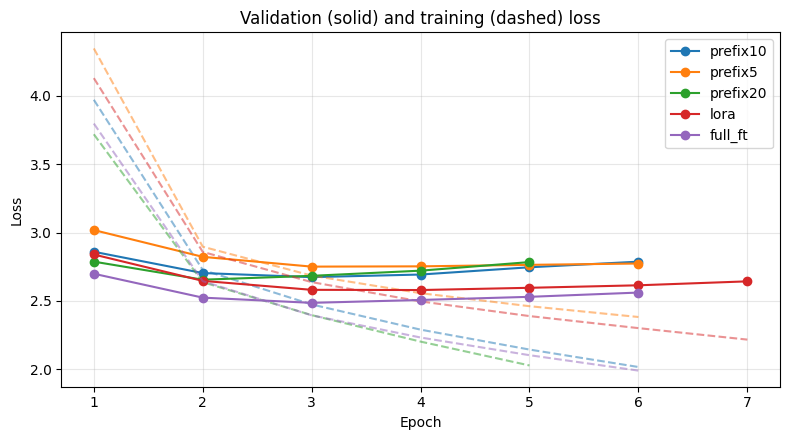

In [15]:
logs = {'prefix10': pd.read_csv(f'{OUT_DIR}/training_log.csv')}
for name in EXPERIMENTS:
    logs[name] = pd.read_csv(f'{OUT_DIR_M3}/training_log_{name}.csv')

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, lg in logs.items():
    line, = ax.plot(lg['epoch'], lg['val_loss'], marker='o', label=name)
    ax.plot(lg['epoch'], lg['train_loss'], linestyle='--', color=line.get_color(), alpha=0.5)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.set_title('Validation (solid) and training (dashed) loss')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{OUT_DIR_M3}/loss_curves.png', dpi=150); plt.show()


> All settings reach their lowest validation loss within 2-4 epochs. After that, the validation loss rises while the training loss keeps decreasing, which indicates overfitting.

## 10. Caption check(only sanity check purpose, not an evaluation)

Generates captions for 3 test images with each model (beam search, no_repeat_ngram_size=3) to confirm that every checkpoint loads and produces sensible captions.

In [16]:
@torch.no_grad()
def quick_caption(m, emb):
    prefix = m.get_prefix(emb.unsqueeze(0).to(device))
    out = m.gpt.generate(inputs_embeds=prefix, attention_mask=torch.ones(prefix.shape[:2], device=device),
                         max_new_tokens=MAX_LEN, num_beams=5, no_repeat_ngram_size=3,
                         eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0], skip_special_tokens=True).split('\n')[0].strip()

check_ids = df[df['split'] == 'test']['image_id'].unique()[:3]
paths = {'prefix10': f'{OUT_DIR}/mapping_net.pt',
         **{name: f'{OUT_DIR_M3}/{name}.pt' for name in EXPERIMENTS}}

caps = {}
for name, path in paths.items():
    m, _ = load_model(path, device)
    print(f'--- {name}')
    caps[name] = {}
    for i in check_ids:
        caps[name][i] = quick_caption(m, embs[id2row[i]])
        print(f'  {i}:', caps[name][i])
    del m; torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

--- prefix10


/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1477: UserWarning: Passing `no_repeat_ngram_size` with `inputs_embeds` and without `input_ids` to `generate` will apply n-gram constraints only to newly generated tokens, not to the prompt.
  warnings.warn(


... (5 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

--- lora
  4134: a man in a suit and tie holding a glass of wine
  7108: an elephant standing next to a tree
  7784: a person flying a kite in the sky


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

--- full_ft
  4134: a man and woman sitting at a table
  7108: a group of elephants standing next to each other in a field
  7784: a person flying a kite in the air


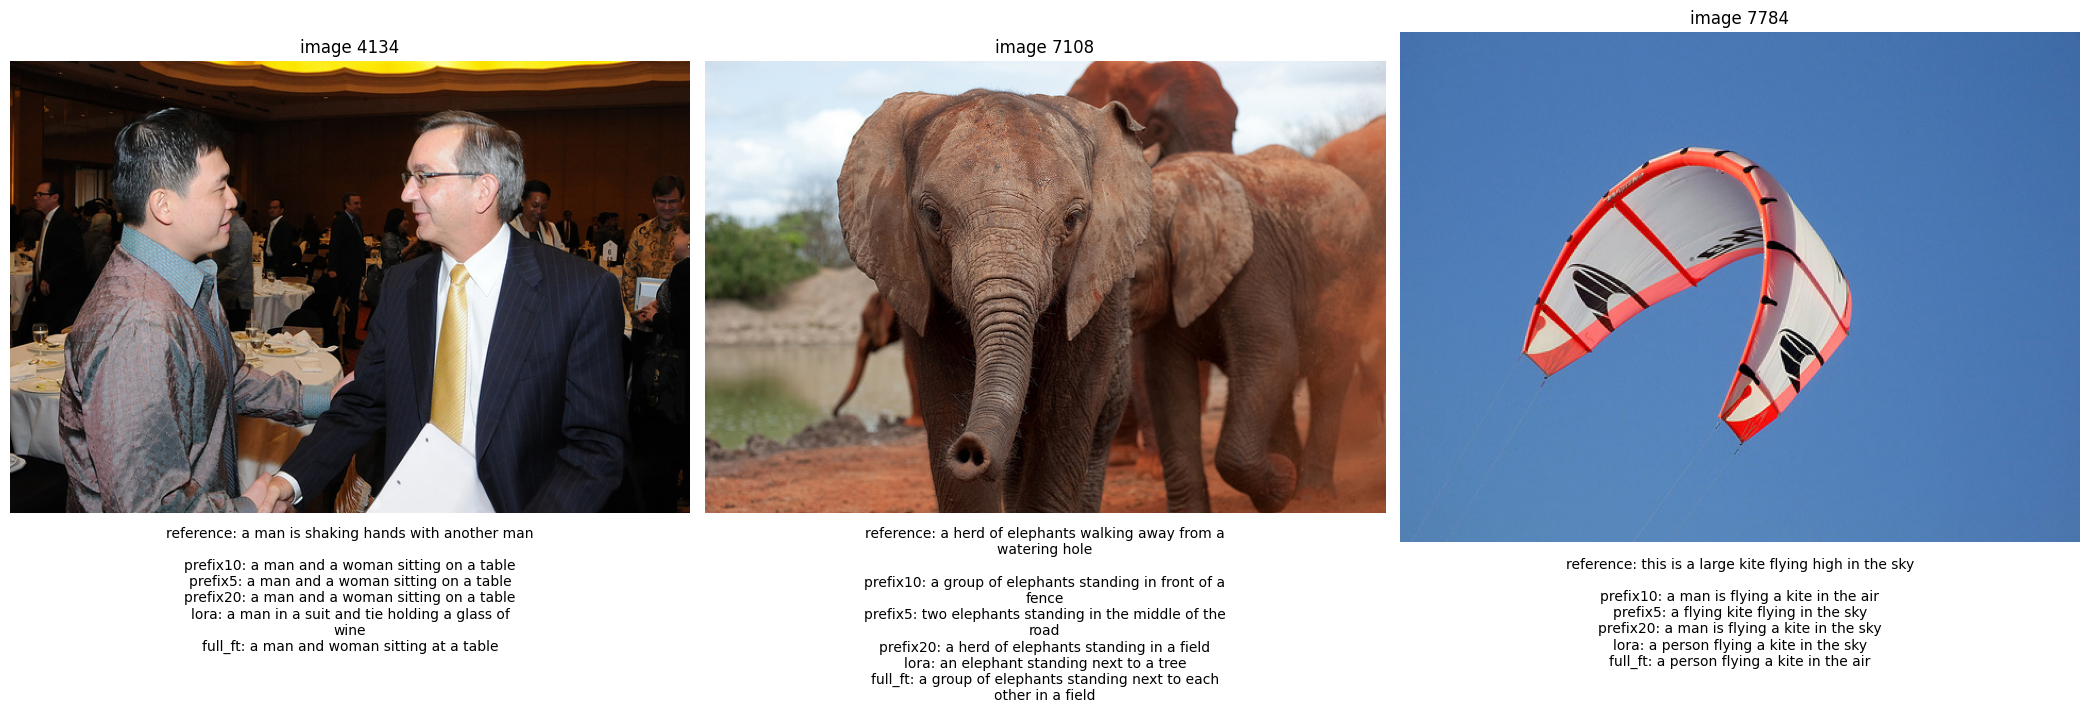

In [17]:
import requests, textwrap
from io import BytesIO
from PIL import Image

def load_coco_image(image_id):
    url = f'http://images.cocodataset.org/val2017/{int(image_id):012d}.jpg'
    return Image.open(BytesIO(requests.get(url, timeout=30).content)).convert('RGB')

wrap = lambda s: '\n'.join(textwrap.wrap(str(s), 45))

fig, axes = plt.subplots(1, len(check_ids), figsize=(7 * len(check_ids), 9))
for ax, i in zip(axes, check_ids):
    ax.imshow(load_coco_image(i))
    ax.axis('off')
    ax.set_title(f'image {i}', fontsize=12)
    ref = df[df['image_id'] == i]['caption'].iloc[0]
    text = f'reference: {wrap(ref)}\n\n' + '\n'.join(f'{name}: {wrap(caps[name][i])}' for name in caps)
    ax.text(0.5, -0.03, text, transform=ax.transAxes, ha='center', va='top', fontsize=10)

plt.tight_layout()
plt.savefig(f'{OUT_DIR_M3}/caption_check.png', dpi=150, bbox_inches='tight')
plt.show()

##  How to use the checkpoints (for evaluation)

| Model | File | Size |
|---|---|---|
| prefix 5 / prefix 20 | `milestone3/prefix5.pt`, `milestone3/prefix20.pt` | mapping network only |
| prefix 10 (Milestone 2) | `milestone2/mapping_net.pt` | mapping network only |
| LoRA / full fine-tuning | `milestone3/lora.pt`, `milestone3/full_ft.pt` | about 600 MB each |


- Load any of them with model, ckpt = load_model(path, device); the prefix length and GPT-2 weights are read from the checkpoint automatically.
- Use L2-normalized CLIP embeddings (NORMALIZE_EMB = True), as in training.
- Generate with model.get_prefix(emb) and model.gpt.generate(inputs_embeds=...), and keep only the first line of the decoded text.
- The LoRA weights are already merged into GPT-2, so peft is not needed for loading.

---
# Part B — Evaluation

Evaluates the five checkpoints on the **test split (100 images, 5 reference captions each)**.

| Step | What it does | Output |
|---|---|---|
| 11 | Install metric tools, evaluation settings, test data | |
| 12 | Caption generation and metric functions (BLEU, METEOR, ROUGE-L, CIDEr, CLIPScore) | |
| 13 | 5 models × 3 decoding strategies (greedy, beam, nucleus) | `eval/generated_all.csv` |
| 14 | Main results: fine-tuning strategies and prefix lengths (beam search) | `eval/metrics_main.csv` |
| 15 | Decoding-strategy comparison + plot | `eval/metrics_decoding.csv`, `eval/metrics_by_decoding.png` |
| 16 | Parameter sensitivity: beam width and temperature + plot | `eval/sensitivity.csv`, `eval/sensitivity.png` |
| 17 | Qualitative alignment: best and worst captions with images | `eval/qualitative_examples.png` |

Generated captions are cached in `eval/`; set `REGENERATE = True` to generate them again.
Run sections 0–4 first (data, tokenizer, model classes, `load_model`). Training (section 7) is skipped because every experiment has `run=False`.

## 11. Evaluation setup

- **pycocoevalcap** provides the standard COCO caption metrics. METEOR in this package runs on Java, which is installed if missing; if Java METEOR fails, NLTK's METEOR is used instead (scores are not identical between the two, so all rows use the same backend). In this run, METEOR was computed with NLTK, which gives higher values than the official COCO METEOR, so METEOR should only be compared within this notebook.
- Captions and references are lowercased and stripped of punctuation before scoring.
- Sampling-based settings (nucleus, temperature) are generated with 3 seeds and their scores are averaged.

In [18]:
!pip install -q pycocoevalcap
import shutil
if shutil.which('java') is None:
    !apt-get -qq install -y default-jre-headless > /dev/null
print('java available:', shutil.which('java') is not None)

java available: True


In [19]:
# ===== Evaluation settings =====
EVAL_DIR = f'{OUT_DIR_M3}/eval'
os.makedirs(EVAL_DIR, exist_ok=True)

MODEL_PATHS = {                                   # same order as the comparison in the report
    'prefix5' : f'{OUT_DIR_M3}/prefix5.pt',
    'prefix10': f'{OUT_DIR}/mapping_net.pt',      # Milestone 2 model
    'prefix20': f'{OUT_DIR_M3}/prefix20.pt',
    'lora'    : f'{OUT_DIR_M3}/lora.pt',
    'full_ft' : f'{OUT_DIR_M3}/full_ft.pt',
}
DECODING = {
    'greedy' : dict(do_sample=False, num_beams=1),
    'beam'   : dict(do_sample=False, num_beams=5),                          # Milestone 2 baseline
    'nucleus': dict(do_sample=True, top_p=0.9, top_k=0, temperature=1.0),   # top_k=0: pure nucleus sampling
}
NO_REPEAT    = 3            # no_repeat_ngram_size, as in the Milestone 2 baseline
SAMPLE_SEEDS = [0, 1, 2]    # seeds for sampling-based settings
GEN_BATCH    = 25

SENS_MODEL   = 'full_ft'    # model used for the sensitivity analysis
BEAM_WIDTHS  = [1, 3, 5, 10]
TEMPERATURES = [0.5, 0.7, 1.0, 1.3]

REGENERATE   = False        # True: ignore cached captions and generate again
for k, p in MODEL_PATHS.items():
    print(f'{k:<9} {"ok" if os.path.exists(p) else "MISSING"}  {p}')

prefix5   ok  /content/drive/MyDrive/IE7615_generative/milestone3/prefix5.pt
prefix10  ok  /content/drive/MyDrive/IE7615_generative/milestone2/mapping_net.pt
prefix20  ok  /content/drive/MyDrive/IE7615_generative/milestone3/prefix20.pt
lora      ok  /content/drive/MyDrive/IE7615_generative/milestone3/lora.pt
full_ft   ok  /content/drive/MyDrive/IE7615_generative/milestone3/full_ft.pt


In [20]:
# Test data: 100 images, 5 references each, L2-normalized CLIP embeddings (same as training)
test_df  = df[df['split'] == 'test']
test_ids = sorted(test_df['image_id'].unique())
refs     = {i: test_df.loc[test_df['image_id'] == i, 'caption'].tolist() for i in test_ids}
test_embs = embs[[id2row[i] for i in test_ids]]
print(f'test images: {len(test_ids)} | references per image: {min(map(len, refs.values()))}–{max(map(len, refs.values()))}')

test images: 100 | references per image: 5–5


## 12. Generation and metric functions

- `generate_captions`: batched generation from the image prefix, keeping the first line of each caption (as in Milestone 2).
- `compute_metrics`: BLEU-1/4, METEOR, ROUGE-L and CIDEr against the 5 references, plus average caption length and distinct-1 (unique words / all words, a simple diversity measure).
- `clip_score`: **CLIPScore** = 2.5 × max(cosine(image, caption), 0) using the same CLIP ViT-B/32. It measures image–caption alignment without references and is used for the qualitative-alignment part.

In [21]:
import re, io, contextlib
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider

@torch.no_grad()
def generate_captions(m, emb_all, **kw):
    caps = []
    for s in range(0, len(emb_all), GEN_BATCH):
        prefix = m.get_prefix(emb_all[s:s + GEN_BATCH].to(device))
        out = m.gpt.generate(inputs_embeds=prefix,
                             attention_mask=torch.ones(prefix.shape[:2], dtype=torch.long, device=device),
                             max_new_tokens=MAX_LEN, no_repeat_ngram_size=NO_REPEAT,
                             eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.eos_token_id, **kw)
        caps += [tokenizer.decode(seq, skip_special_tokens=True).split('\n')[0].strip() for seq in out]
    return caps

def norm(s):
    return ' '.join(re.findall(r"[a-z0-9]+(?:'[a-z]+)?", str(s).lower()))

# METEOR: Java version from pycocoevalcap, NLTK as a fallback
try:
    from pycocoevalcap.meteor.meteor import Meteor
    _meteor = Meteor()
    _meteor.compute_score({0: ['a dog runs']}, {0: ['a dog runs']})
    METEOR_BACKEND = 'pycocoevalcap (Java)'
except Exception as err:
    import nltk
    from nltk.translate.meteor_score import meteor_score
    nltk.download('wordnet', quiet=True); nltk.download('omw-1.4', quiet=True)
    _meteor, METEOR_BACKEND = None, f'nltk (Java METEOR failed: {type(err).__name__})'
print('METEOR backend:', METEOR_BACKEND)

def meteor_fn(gts, res):
    if _meteor is not None:
        return _meteor.compute_score(gts, res)[0]
    return float(np.mean([meteor_score([r.split() for r in gts[k]], res[k][0].split()) for k in gts]))

def compute_metrics(caps):
    gts = {i: [norm(r) for r in refs[i]] for i in test_ids}
    res = {i: [norm(c) or 'empty'] for i, c in zip(test_ids, caps)}
    with contextlib.redirect_stdout(io.StringIO()):          # pycocoevalcap prints debug lines
        bleu, _ = Bleu(4).compute_score(gts, res)
        rouge, _ = Rouge().compute_score(gts, res)
        cider, cider_img = Cider().compute_score(gts, res)
    words = [w for v in res.values() for w in v[0].split()]
    scores = dict(BLEU1=bleu[0] * 100, BLEU4=bleu[3] * 100, METEOR=meteor_fn(gts, res) * 100,
                  ROUGE_L=rouge * 100, CIDEr=cider * 100,
                  avg_len=len(words) / len(res), distinct1=len(set(words)) / max(1, len(words)))
    return scores, dict(zip(test_ids, cider_img * 100))

# CLIPScore with the same CLIP model as Milestone 1
from transformers import CLIPModel, CLIPTokenizer
clip_model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device).eval()
clip_tok   = CLIPTokenizer.from_pretrained('openai/clip-vit-base-patch32')
img_feat   = test_embs.to(device)                                   # already L2-normalized

@torch.no_grad()
def clip_score(caps):
    t = clip_tok([str(c) for c in caps], padding=True, truncation=True, max_length=77, return_tensors='pt').to(device)
    txt = clip_model.text_projection(clip_model.text_model(**t).pooler_output)
    txt = txt / txt.norm(dim=-1, keepdim=True)
    cos = (txt * img_feat).sum(-1)
    per_img = 2.5 * cos.clamp(min=0)
    return per_img.mean().item() * 100, per_img.cpu().numpy() * 100

METRICS = ['BLEU1', 'BLEU4', 'METEOR', 'ROUGE_L', 'CIDEr', 'CLIPScore', 'avg_len', 'distinct1']
ref_clip = clip_score([refs[i][0] for i in test_ids])[0]
print(f'CLIPScore of the first reference caption (upper reference point): {ref_clip:.1f}')

METEOR backend: nltk (Java METEOR failed: ValueError)


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIPScore of the first reference caption (upper reference point): 74.5


## 13. Generate captions: 5 models × 3 decoding strategies

Each model is loaded once and generates captions for the 100 test images with every decoding strategy (nucleus: 3 seeds).
The LoRA and full fine-tuning checkpoints are about 600 MB each, so models are loaded one at a time.

In [22]:
gen_path = f'{EVAL_DIR}/generated_all.csv'
if os.path.exists(gen_path) and not REGENERATE:
    gen = pd.read_csv(gen_path)
    print('loaded cached captions:', gen_path)
else:
    rows = []
    for mname, path in MODEL_PATHS.items():
        t0 = time.time()
        m, _ = load_model(path, device)
        for dname, kw in DECODING.items():
            for sd in (SAMPLE_SEEDS if kw.get('do_sample') else [-1]):
                if sd >= 0:
                    torch.manual_seed(sd)
                caps = generate_captions(m, test_embs, **kw)
                rows += [dict(model=mname, decoding=dname, seed=sd, image_id=i, caption=c) for i, c in zip(test_ids, caps)]
        del m; torch.cuda.empty_cache()
        print(f'{mname:<9} done ({time.time() - t0:.0f}s)')
    gen = pd.DataFrame(rows)
    gen.to_csv(gen_path, index=False)
gen['caption'] = gen['caption'].fillna('')
print(len(gen), 'captions')

loaded cached captions: /content/drive/MyDrive/IE7615_generative/milestone3/eval/generated_all.csv
2500 captions


In [23]:
records, cider_per_img, clip_per_img = [], {}, {}
for (mname, dname, sd), g in gen.groupby(['model', 'decoding', 'seed'], sort=False):
    caps = g.set_index('image_id').loc[test_ids, 'caption'].tolist()
    scores, cimg = compute_metrics(caps)
    scores['CLIPScore'], clip_img = clip_score(caps)
    records.append(dict(model=mname, decoding=dname, seed=sd, **scores))
    cider_per_img[(mname, dname, sd)] = cimg
    clip_per_img[(mname, dname, sd)] = dict(zip(test_ids, clip_img))

raw = pd.DataFrame(records)
summary = raw.groupby(['model', 'decoding'], sort=False)[METRICS].mean().reset_index()   # nucleus: mean of 3 seeds
summary.round(3).to_csv(f'{EVAL_DIR}/metrics_all.csv', index=False)
print('scored', len(raw), 'caption sets')

scored 25 caption sets


## 14. Main results: fine-tuning strategies and prefix lengths

All models decoded with **beam search (5 beams, no_repeat_ngram_size = 3)**, the Milestone 2 baseline. BLEU, METEOR, ROUGE-L, CIDEr and CLIPScore are shown × 100. The validation loss comes from the training comparison (section 8).

In [24]:
order = list(MODEL_PATHS)
main = summary[summary['decoding'] == 'beam'].set_index('model').loc[order].reset_index()
train_cmp = pd.read_csv(f'{OUT_DIR_M3}/training_comparison.csv')[['experiment', 'mode', 'trainable_params', 'best_val_loss']]
main = main.merge(train_cmp, left_on='model', right_on='experiment', how='left').drop(columns=['experiment', 'decoding'])
main = main[['model', 'mode', 'trainable_params', 'best_val_loss'] + METRICS]
main.round(2).to_csv(f'{EVAL_DIR}/metrics_main.csv', index=False)
print(f'METEOR backend: {METEOR_BACKEND} | CLIPScore of references: {ref_clip:.1f}')
main.round(2)

METEOR backend: nltk (Java METEOR failed: ValueError) | CLIPScore of references: 74.5


,model,mode,trainable_params,best_val_loss,BLEU1,BLEU4,METEOR,ROUGE_L,CIDEr,CLIPScore,avg_len,distinct1
0,prefix5,frozen,8361600,2.75,58.39,15.25,35.82,42.71,56.97,64.41,10.07,0.16
1,prefix10,frozen,31468800,2.67,62.08,17.98,38.61,45.47,63.90,66.47,9.73,0.18
2,prefix20,frozen,121920000,2.65,58.91,14.49,37.22,43.20,61.84,66.63,10.78,0.18
3,lora,lora,31763712,2.58,64.81,18.71,39.54,46.04,74.39,68.69,9.50,0.22
4,full_ft,full,155908608,2.49,62.16,17.52,39.71,45.40,67.62,65.90,10.20,0.20


## 15. Decoding strategies across models

Same 100 test images, same five models; only the decoding strategy changes. Nucleus scores are averaged over 3 seeds.

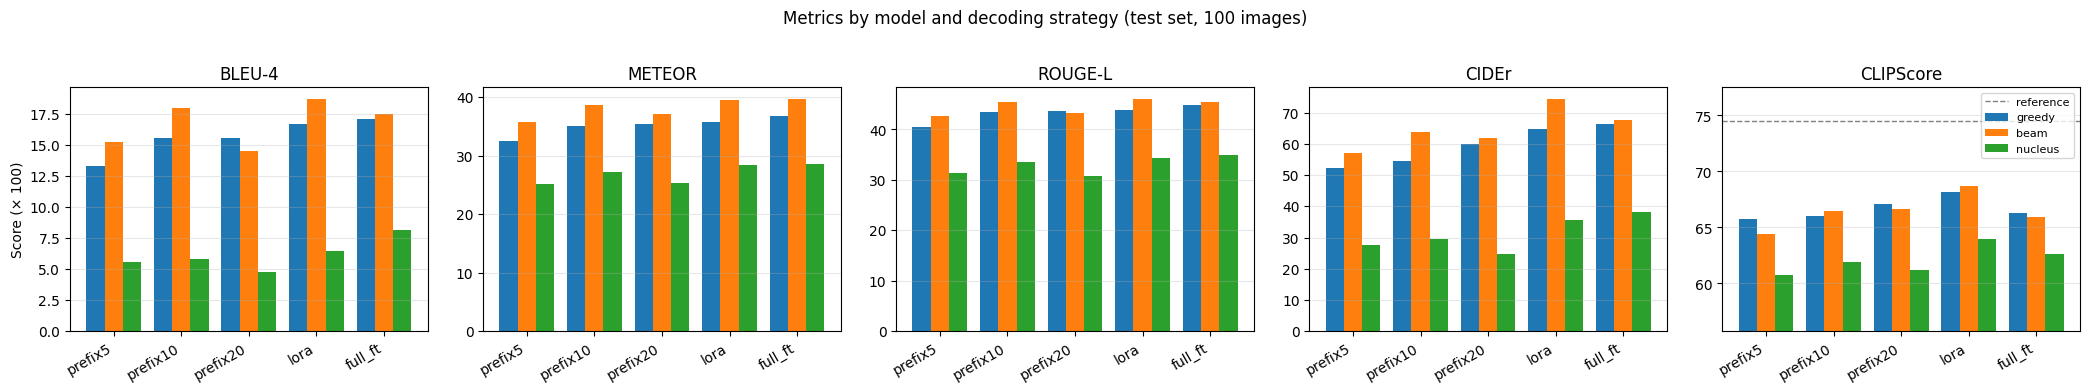

CIDEr                 BLEU4                METEOR                 \
decoding greedy   beam nucleus greedy   beam nucleus greedy   beam nucleus   
model                                                                        
prefix5   52.35  56.97   27.73  13.33  15.25    5.59  32.51  35.82   25.24   
prefix10  54.51  63.90   29.44  15.54  17.98    5.83  35.08  38.61   27.17   
prefix20  59.89  61.84   24.71  15.54  14.49    4.75  35.37  37.22   25.42   
lora      64.85  74.39   35.52  16.72  18.71    6.43  35.85  39.54   28.46   
full_ft   66.28  67.62   38.17  17.12  17.52    8.18  36.83  39.71   28.58   

         ROUGE_L                CLIPScore                distinct1        \
decoding  greedy   beam nucleus    greedy   beam nucleus    greedy  beam   
model                                                                      
prefix5    40.48  42.71   31.45     65.78  64.41   60.72      0.19  0.16   
prefix10   43.46  45.47   33.49     66.03  66.47   61.94      0.20  0.18   
prefix20   43.64  43.20   30.80     67.06  66.63   61.24      0.20  0.18   
lora       43.78  46.04   34.29     68.19  68.69   63.95      0.22  0.22   
full_ft    44.83  45.40   35.03     66.26  65.90   62.66      0.21  0.20   

                  
decoding nucleus  
model             
prefix5     0.36  
prefix10    0.36  
prefix20    0.37  
lora        0.35  
full_ft     0.32

In [25]:
dec = summary.pivot(index='model', columns='decoding', values=['CIDEr', 'BLEU4', 'METEOR', 'ROUGE_L', 'CLIPScore', 'distinct1'])
dec = dec.loc[order].reindex(columns=list(DECODING), level=1)
dec.round(2).to_csv(f'{EVAL_DIR}/metrics_decoding.csv')

panels = [('BLEU4', 'BLEU-4'), ('METEOR', 'METEOR'), ('ROUGE_L', 'ROUGE-L'), ('CIDEr', 'CIDEr'), ('CLIPScore', 'CLIPScore')]
fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8))
x, w = np.arange(len(order)), 0.27
for ax, (col, title) in zip(axes, panels):
    for k, d in enumerate(DECODING):
        vals = summary[summary['decoding'] == d].set_index('model').loc[order, col]
        ax.bar(x + (k - 1) * w, vals, w, label=d)
    ax.set_xticks(x); ax.set_xticklabels(order, rotation=30, ha='right')
    ax.set_title(title); ax.grid(axis='y', alpha=0.3)
    if col == 'CLIPScore':
        ax.set_ylim(summary[col].min() - 5, max(summary[col].max(), ref_clip) + 3)
        ax.axhline(ref_clip, color='gray', ls='--', lw=1, label='reference')
axes[0].set_ylabel('Score (× 100)'); axes[-1].legend(fontsize=8)
plt.suptitle('Metrics by model and decoding strategy (test set, 100 images)', y=1.02)
plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/metrics_by_decoding.png', dpi=150, bbox_inches='tight'); plt.show()
dec.round(2)

## 16. Parameter sensitivity: beam width and temperature

One model (`SENS_MODEL` = `full_ft`, the model with the lowest validation loss, chosen before the evaluation) is decoded with different settings:
- **Beam width** 1, 3, 5, 10 (beam width 1 = greedy decoding)
- **Temperature** 0.5, 0.7, 1.0, 1.3 with nucleus sampling (top-p 0.9), 3 seeds each (mean ± standard deviation)

Embedding injection is analyzed through the prefix length (5, 10, 20) in section 14, because cross-attention was not implemented (see the top of the notebook).

In [26]:
sens_gen_path = f'{EVAL_DIR}/sensitivity_captions.csv'
if os.path.exists(sens_gen_path) and not REGENERATE:
    sens_gen = pd.read_csv(sens_gen_path)
    print('loaded cached captions:', sens_gen_path)
else:
    m, _ = load_model(MODEL_PATHS[SENS_MODEL], device)
    rows = []
    for bw in BEAM_WIDTHS:
        caps = generate_captions(m, test_embs, do_sample=False, num_beams=bw)
        rows += [dict(param='beam_width', value=bw, seed=-1, image_id=i, caption=c) for i, c in zip(test_ids, caps)]
    for T in TEMPERATURES:
        for sd in SAMPLE_SEEDS:
            torch.manual_seed(sd)
            caps = generate_captions(m, test_embs, do_sample=True, top_p=0.9, top_k=0, temperature=T)
            rows += [dict(param='temperature', value=T, seed=sd, image_id=i, caption=c) for i, c in zip(test_ids, caps)]
    del m; torch.cuda.empty_cache()
    sens_gen = pd.DataFrame(rows)
    sens_gen.to_csv(sens_gen_path, index=False)
sens_gen['caption'] = sens_gen['caption'].fillna('')

rec = []
for (p, v, sd), g in sens_gen.groupby(['param', 'value', 'seed'], sort=False):
    caps = g.set_index('image_id').loc[test_ids, 'caption'].tolist()
    s, _ = compute_metrics(caps)
    s['CLIPScore'] = clip_score(caps)[0]
    rec.append(dict(param=p, value=v, seed=sd, **s))
sens_raw = pd.DataFrame(rec)
sens = sens_raw.groupby(['param', 'value'])[METRICS].agg(['mean', 'std'])
sens.round(3).to_csv(f'{EVAL_DIR}/sensitivity.csv')
sens.xs('mean', axis=1, level=1).round(2)

loaded cached captions: /content/drive/MyDrive/IE7615_generative/milestone3/eval/sensitivity_captions.csv


BLEU1  BLEU4  METEOR  ROUGE_L  CIDEr  CLIPScore  avg_len  \
param       value                                                             
beam_width  1.0    62.91  17.12   36.83    44.83  66.28      66.26     9.15   
            3.0    64.03  18.03   38.35    44.98  68.76      65.97     9.62   
            5.0    62.16  17.52   39.71    45.40  67.62      65.90    10.20   
            10.0   60.97  16.78   38.81    44.83  67.28      65.29    10.48   
temperature 0.5    59.71  14.49   34.79    42.47  61.25      66.51     9.68   
            0.7    56.35  12.57   32.35    39.43  51.73      65.04     9.61   
            1.0    49.15   8.18   28.58    35.03  38.17      62.66    10.09   
            1.3    33.17   3.38   20.11    25.09  19.40      59.61    10.92   

                   distinct1  
param       value             
beam_width  1.0         0.21  
            3.0         0.20  
            5.0         0.20  
            10.0        0.18  
temperature 0.5         0.23  
            0.7         0.26  
            1.0         0.32  
            1.3         0.45

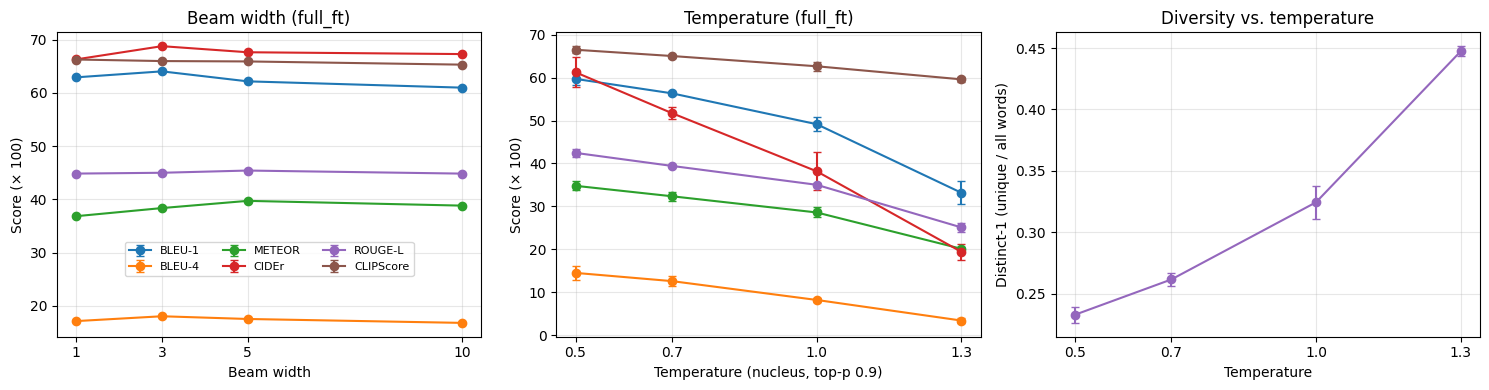

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cols = [('BLEU1', 'BLEU-1'), ('BLEU4', 'BLEU-4'), ('METEOR', 'METEOR'), ('CIDEr', 'CIDEr'),
        ('ROUGE_L', 'ROUGE-L'), ('CLIPScore', 'CLIPScore')]

for p, ax, xlabel in [('beam_width', axes[0], 'Beam width'), ('temperature', axes[1], 'Temperature (nucleus, top-p 0.9)')]:
    part = sens.loc[p]
    for col, lab in cols:
        ax.errorbar(part.index, part[(col, 'mean')], yerr=part[(col, 'std')].fillna(0), marker='o', capsize=3, label=lab)
    ax.set_xlabel(xlabel); ax.set_ylabel('Score (× 100)'); ax.grid(alpha=0.3)
    ax.set_xticks(part.index)
axes[0].set_title(f'Beam width ({SENS_MODEL})'); axes[1].set_title(f'Temperature ({SENS_MODEL})')
axes[0].legend(fontsize=8, ncol=3, loc='lower center', bbox_to_anchor=(0.5, 0.18))

part = sens.loc['temperature']
axes[2].errorbar(part.index, part[('distinct1', 'mean')], yerr=part[('distinct1', 'std')], marker='o', capsize=3, color='tab:purple')
axes[2].set_xlabel('Temperature'); axes[2].set_ylabel('Distinct-1 (unique / all words)')
axes[2].set_title('Diversity vs. temperature'); axes[2].grid(alpha=0.3); axes[2].set_xticks(part.index)
plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/sensitivity.png', dpi=150, bbox_inches='tight'); plt.show()

## 17. Qualitative alignment between image and caption

The two test images with the highest and the two with the lowest CIDEr for `full_ft` (lowest validation loss, beam search) are shown with a reference caption and the beam-search captions of the Milestone 2 model (`prefix10`) and `full_ft`. CLIPScore (× 100) is given for each generated caption.



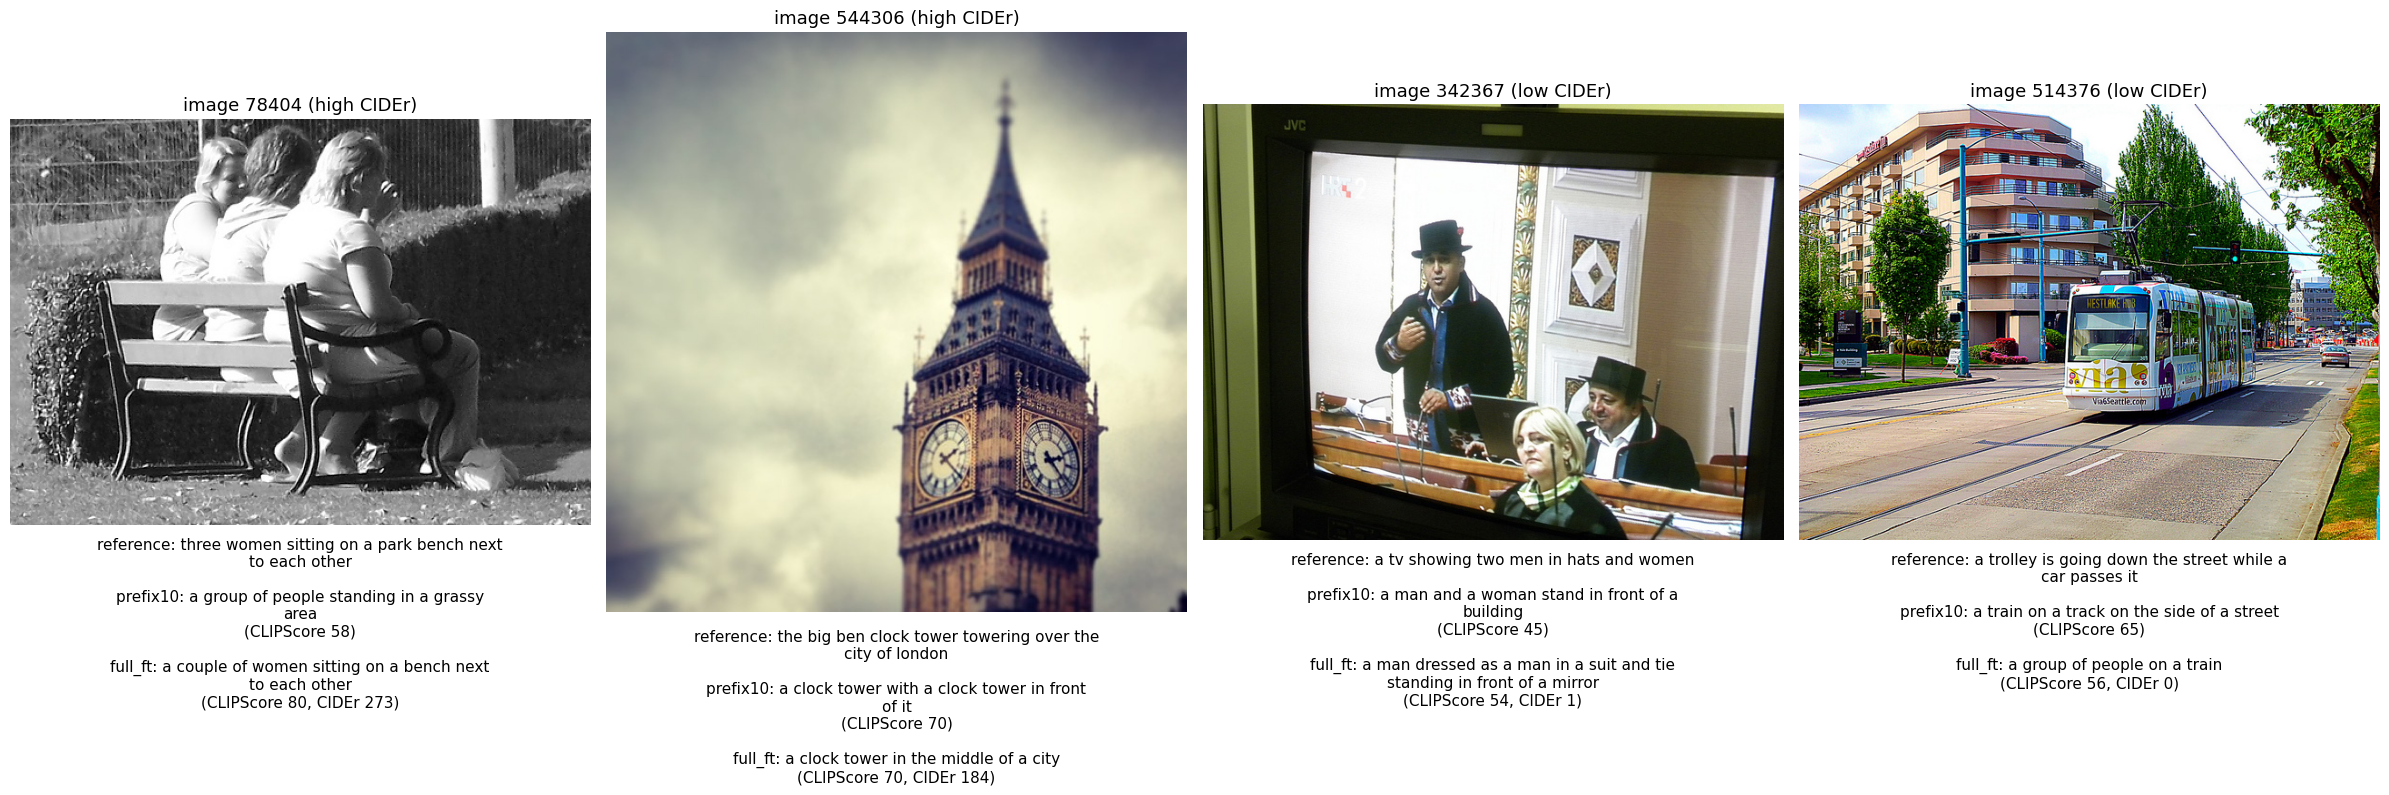

In [28]:
import requests, textwrap
from io import BytesIO
from PIL import Image

def load_coco_image(image_id):
    local = f'/content/coco/val2017/{int(image_id):012d}.jpg'
    if os.path.exists(local):
        return Image.open(local).convert('RGB')
    url = f'http://images.cocodataset.org/val2017/{int(image_id):012d}.jpg'
    return Image.open(BytesIO(requests.get(url, timeout=30).content)).convert('RGB')

wrap = lambda s: '\n'.join(textwrap.wrap(str(s), 42))
best_key, base_key = ('full_ft', 'beam', -1), ('prefix10', 'beam', -1)
ranked = sorted(test_ids, key=lambda i: cider_per_img[best_key][i], reverse=True)
show = ranked[:2] + ranked[-2:]
cap_of = lambda key, i: gen[(gen.model == key[0]) & (gen.decoding == key[1]) & (gen.seed == key[2]) & (gen.image_id == i)]['caption'].iloc[0]

fig, axes = plt.subplots(1, 4, figsize=(24, 8.5))
for ax, i, tag in zip(axes, show, ['high CIDEr', 'high CIDEr', 'low CIDEr', 'low CIDEr']):
    ax.imshow(load_coco_image(i)); ax.axis('off')
    ax.set_title(f'image {i} ({tag})', fontsize=13)
    text = (f'reference: {wrap(refs[i][0])}\n\n'
            f'prefix10: {wrap(cap_of(base_key, i))}\n(CLIPScore {clip_per_img[base_key][i]:.0f})\n\n'
            f'full_ft: {wrap(cap_of(best_key, i))}\n(CLIPScore {clip_per_img[best_key][i]:.0f}, CIDEr {cider_per_img[best_key][i]:.0f})')
    ax.text(0.5, -0.03, text, transform=ax.transAxes, ha='center', va='top', fontsize=11)
plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/qualitative_examples.png', dpi=150, bbox_inches='tight'); plt.show()

In [34]:
# Summary of the evaluation results
from IPython.display import display, Markdown

HL = 'background-color: #c6efce; color: #000; font-weight: bold'   # highlight for the best values

best     = main.loc[main['CIDEr'].idxmax()]
low_loss = main.loc[main['best_val_loss'].idxmin()]
dec_cols = ['CIDEr', 'BLEU4', 'METEOR', 'ROUGE_L', 'CLIPScore', 'distinct1']
dec_mean = summary.groupby('decoding', sort=False)[dec_cols].mean().loc[list(DECODING)]
bw     = sens.loc['beam_width'][('CIDEr', 'mean')]
tp     = sens.loc['temperature'][('CIDEr', 'mean')]
tp_div = sens.loc['temperature'][('distinct1', 'mean')]

# 1) Key findings
key = pd.DataFrame([
    ['Best model (beam search, CIDEr)', best['model'],
     f"CIDEr {best['CIDEr']:.1f} · BLEU-4 {best['BLEU4']:.1f} · CLIPScore {best['CLIPScore']:.1f}"],
    ['Lowest validation loss', low_loss['model'],
     f"val loss {low_loss['best_val_loss']:.3f} · CIDEr {low_loss['CIDEr']:.1f}"],
    ['Best decoding (mean CIDEr over 5 models)', dec_mean['CIDEr'].idxmax(),
     f"CIDEr {dec_mean['CIDEr'].max():.1f}"],
    ['Most diverse decoding (distinct-1)', dec_mean['distinct1'].idxmax(),
     f"distinct-1 {dec_mean['distinct1'].max():.3f}"],
    [f'Best beam width ({SENS_MODEL})', f'{bw.idxmax():g}',
     f'CIDEr {bw.max():.1f} (range {bw.min():.1f}–{bw.max():.1f})'],
    [f'Best temperature ({SENS_MODEL})', f'{tp.idxmax():g}',
     f'CIDEr {tp.max():.1f} → {tp.min():.1f} at {tp.idxmin():g}; distinct-1 {tp_div.min():.2f} → {tp_div.max():.2f}'],
    ['CLIPScore: reference captions', f'{ref_clip:.1f}',
     f"{best['model']}: {best['CLIPScore']:.1f} ({best['CLIPScore'] / ref_clip:.0%} of the reference)"],
], columns=['Finding', 'Result', 'Details'])

display(Markdown('### Key results (test set, 100 images)'))
display(Markdown(f'METEOR backend: `{METEOR_BACKEND}`'))
display(key.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

# 2) Models with beam search
display(Markdown('### Models with beam search (× 100; best value highlighted)'))
mcols = ['best_val_loss', 'BLEU1', 'BLEU4', 'METEOR', 'ROUGE_L', 'CIDEr', 'CLIPScore', 'distinct1']
display(main.set_index('model')[mcols].style.format(precision=2)
        .highlight_max(subset=mcols[1:], props=HL)
        .highlight_min(subset=['best_val_loss'], props=HL))

# 3) Decoding strategies (mean over 5 models)
display(Markdown('### Decoding strategies (mean over 5 models; nucleus = mean of 3 seeds)'))
display(dec_mean.style.format(precision=2).highlight_max(props=HL))

# 4) Sensitivity
display(Markdown(f'### Sensitivity ({SENS_MODEL})'))
scols = ['BLEU4', 'METEOR', 'ROUGE_L', 'CIDEr', 'CLIPScore', 'avg_len', 'distinct1']
sens_mean = sens.xs('mean', axis=1, level=1)[scols]
display(sens_mean.style.format(precision=2)
        .highlight_max(subset=pd.IndexSlice['beam_width', scols], props=HL)
        .highlight_max(subset=pd.IndexSlice['temperature', scols], props=HL))

# 5) Saved files
display(Markdown(f'### Files in `{EVAL_DIR}`'))
files = pd.DataFrame([(fn, round(os.path.getsize(f'{EVAL_DIR}/{fn}') / 1e6, 2)) for fn in sorted(os.listdir(EVAL_DIR))],
                     columns=['file', 'size (MB)'])
display(files.style.hide(axis='index'))

### Key results (test set, 100 images)

METEOR backend: `nltk (Java METEOR failed: ValueError)`

Finding,Result,Details
"Best model (beam search, CIDEr)",lora,CIDEr 74.4 · BLEU-4 18.7 · CLIPScore 68.7
Lowest validation loss,full_ft,val loss 2.485 · CIDEr 67.6
Best decoding (mean CIDEr over 5 models),beam,CIDEr 64.9
Most diverse decoding (distinct-1),nucleus,distinct-1 0.353
Best beam width (full_ft),3,CIDEr 68.8 (range 66.3–68.8)
Best temperature (full_ft),0.5,CIDEr 61.3 → 19.4 at 1.3; distinct-1 0.23 → 0.45
CLIPScore: reference captions,74.5,lora: 68.7 (92% of the reference)


### Models with beam search (× 100; best value highlighted)

,best_val_loss,BLEU1,BLEU4,METEOR,ROUGE_L,CIDEr,CLIPScore,distinct1
model,,,,,,,,
prefix5,2.75,58.39,15.25,35.82,42.71,56.97,64.41,0.16
prefix10,2.67,62.08,17.98,38.61,45.47,63.90,66.47,0.18
prefix20,2.65,58.91,14.49,37.22,43.20,61.84,66.63,0.18
lora,2.58,64.81,18.71,39.54,46.04,74.39,68.69,0.22
full_ft,2.49,62.16,17.52,39.71,45.40,67.62,65.90,0.20


### Decoding strategies (mean over 5 models; nucleus = mean of 3 seeds)

,CIDEr,BLEU4,METEOR,ROUGE_L,CLIPScore,distinct1
decoding,,,,,,
greedy,59.58,15.65,35.13,43.24,66.66,0.20
beam,64.95,16.79,38.18,44.56,66.42,0.19
nucleus,31.11,6.16,26.97,33.01,62.10,0.35


### Sensitivity (full_ft)

### Files in `/content/drive/MyDrive/IE7615_generative/milestone3/eval`

file,size (MB)
generated_all.csv,0.180000
metrics_all.csv,0.000000
metrics_by_decoding.png,0.080000
metrics_decoding.csv,0.000000
metrics_main.csv,0.000000
qualitative_examples.png,3.580000
sensitivity.csv,0.000000
sensitivity.png,0.140000
sensitivity_captions.csv,0.120000
